In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression    
#LinearRegression permite modelar modelos de regresion simple y múltiple

In [4]:
path="../data/Obesidad_Infantil.csv"
encoding="latin1"
df=pd.read_csv(path, encoding=encoding)
df.shape

(313, 7)

In [6]:
#Revisamos cual es la variable más correlacionada
df.corr()

C:\Users\Ivan galeno reyes\AppData\Local\Temp\ipykernel_16792\2102529375.py:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.corr()


,PESO (KG),TALLA (MT),CIRCUNFERENCIA DE CINTURA,EDAD,ÍNDICE CINTURA/TALLA,IMC
PESO (KG),1.000000,0.830357,0.913062,0.629323,0.511282,0.884710
TALLA (MT),0.830357,1.000000,0.631897,0.855203,0.026385,0.504175
CIRCUNFERENCIA DE CINTURA,0.913062,0.631897,1.000000,0.415179,0.786955,0.930365
EDAD,0.629323,0.855203,0.415179,1.000000,-0.139436,0.312798
ÍNDICE CINTURA/TALLA,0.511282,0.026385,0.786955,-0.139436,1.000000,0.798940
IMC,0.884710,0.504175,0.930365,0.312798,0.798940,1.000000


In [9]:
#Despues de verificar la variable más correlacionada con el PESO (KG)
#Determinar variable predictiva (y) y explicativa (X)

y= df["PESO (KG)"]
X = df[["CIRCUNFERENCIA DE CINTURA"]]
print(y.shape)
X.shape

(313,)


(313, 1)

In [7]:
#Crear el modelo de Regresion
model = LinearRegression()
type(model)

sklearn.linear_model._base.LinearRegression

In [10]:
model.fit(X,y)    #El modelo se ajusta a los datos definidos

LinearRegression()

In [11]:
m = model.coef_[0]     #Pendiente de la recta
b = model.intercept_    #Ordenada al origen
print(f"Valor de m= {m} y valor de b= {b}")

Valor de m= 1.0705755027963928 y valor de b= -34.690094691235906


In [20]:
y_pred = model.predict(X)
print(y_pred.shape)
y_pred

(313,)


array([28.47385997, 17.76810495, 18.3033927 , 14.55637844, 20.97983145,
       24.72684571, 20.97983145, 16.69752944, 18.83868045, 26.33270897,
       19.90925595, 25.26213347, 24.19155796, 16.69752944, 29.54443548,
       19.90925595, 16.69752944, 25.26213347, 26.33270897, 35.96788849,
       24.19155796, 28.47385997, 20.97983145, 18.83868045, 17.23281719,
       20.97983145, 22.05040696, 24.19155796, 30.61501098, 25.26213347,
       24.19155796, 18.83868045, 48.81479453, 18.83868045, 22.05040696,
       19.3739682 , 18.3033927 , 18.83868045, 31.68558648, 22.05040696,
       19.90925595, 31.15029873, 18.83868045, 30.61501098, 16.69752944,
       20.97983145, 22.05040696, 41.85605376, 16.69752944, 24.19155796,
       19.90925595, 23.12098246, 25.26213347, 32.75616198, 23.12098246,
       27.40328447, 24.19155796, 17.76810495, 24.19155796, 27.40328447,
       18.83868045, 28.47385997, 28.47385997, 24.72684571, 18.83868045,
       22.05040696, 24.19155796, 39.179615  , 29.54443548, 32.75

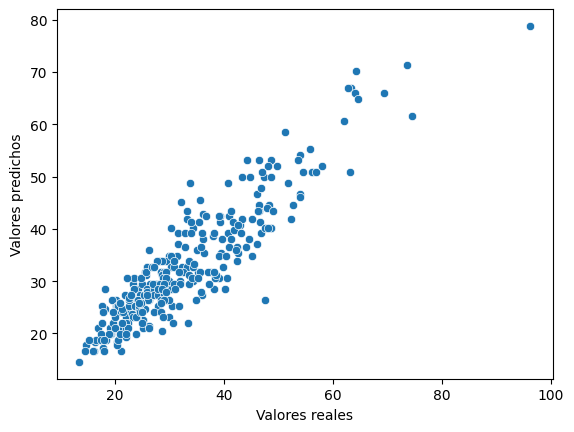

In [18]:
#Visualizar la precision de las predicciones
sns.scatterplot(data=df, x=y, y=y_pred)
plt.xlabel("Valores reales")
plt.ylabel("Valores predichos")
plt.show()

In [ ]:
#Importar libreria de metricas para evaluar desempeño del modelo
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


In [23]:
#Definir los valores r2, mse y mae
r2= r2_score(y, y_pred)
mae= mean_absolute_error(y, y_pred)
mse= mean_squared_error(y, y_pred)

print(f"El valor de r2:{r2:.4f}, el valor mae:{mae:.4f} y el valor mse:{mse:.4f}")

El valor de r2:0.8337, el valor mae:3.7727 y el valor mse:24.3264


In [8]:
df.sample(5)

,PESO (KG),TALLA (MT),CIRCUNFERENCIA DE CINTURA,EDAD,ÍNDICE CINTURA/TALLA,IMC,SEXO
273,34.90,1.49,57.0,10,0.38,15.72,F
18,19.55,1.11,57.0,5,0.51,15.87,M
121,24.30,1.25,57.0,9,0.46,15.55,F
282,62.70,1.49,95.0,11,0.64,28.24,M
291,39.15,1.51,61.0,9,0.40,17.17,F


In [11]:
x57 = model.predict([[61]])
x57

c:\Users\Ivan galeno reyes\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:439: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([30.61501098])